# 📈 50 Startups 多元線性回歸與特徵選擇實證研究
## 依循 CRISP-DM 方法論、5-Fold 交叉驗證、Optuna 調參及 Boston Housing 通用實證

本 Notebook 嚴格依循多元線性回歸課程要求與機器學習嚴謹規範編寫：
- **嚴格防治資料洩漏 (Data Leakage)**：先切分 80% 訓練集與 20% 測試集，前處理參數 (中位數、One-Hot 類別) 100% 僅從訓練集學習。
- **正規特徵選擇 (Feature Selection)**：使用 5-Fold 交叉驗證 (CV) RMSE 作為特徵挑選與模型評估唯一依據，絕不使用測試集挑選特徵。
- **歷史講義示範區**：保留原先以 Test RMSE 貪婪前向選擇之版本作為教學對照，清楚標註評估樂觀偏差。
- **Optuna 超參數調校**：以訓練集 5-Fold CV RMSE 為 Objective，對 Ridge 回歸之 alpha 進行 30 次對數尺度搜尋。
- **Topic 2: Boston Housing**：以通用回歸工作流程 (Workflow) 執行波士頓房價 13 項特徵實證。

## 一、環境依賴與函式庫載入

In [1]:
import os
import sys
import gzip
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.model_selection import train_test_split, KFold, cross_val_score, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV, ElasticNetCV
from sklearn.feature_selection import SelectFromModel, RFE
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from scipy import stats

# 圖表字型設置
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
print('✅ 函式庫載入完成！')

✅ 函式庫載入完成！


## 二、CRISP-DM Phase 1 & 2: Business & Data Understanding
1. 預測目標：企業獲利能力 `Profit` ($)
2. 候選特徵：研發支出 (`R&D Spend`)、行政支出 (`Administration`)、行銷支出 (`Marketing Spend`)、所在州 (`State`)
3. 繪製**教學示範用隨機合成資料散佈圖**（固定種子，標記為教學示範）與**真實資料支出散佈圖**。

真實資料維度：50 筆列資料，5 個欄位


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/4268278942.py:21: UserWarning: Glyph 31034 (\N{CJK UNIFIED IDEOGRAPH-793A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/4268278942.py:21: UserWarning: Glyph 31684 (\N{CJK UNIFIED IDEOGRAPH-7BC4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/4268278942.py:21: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/4268278942.py:21: UserWarning: Glyph 24501 (\N{CJK UNIFIED IDEOGRAPH-5FB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/4268278942.py:21: UserWarning: Glyph 35722 (\N{CJK UNIFIED IDEOGRAPH-8B8A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j

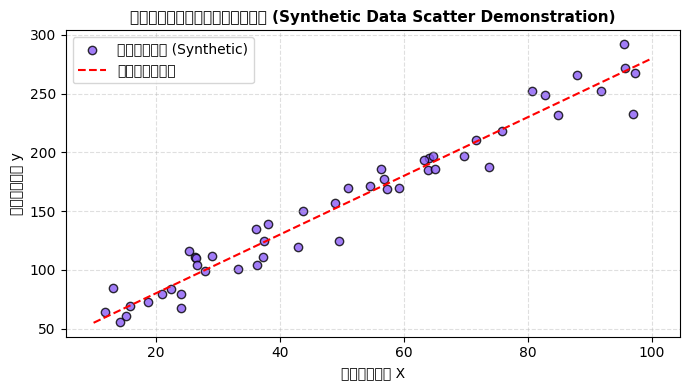

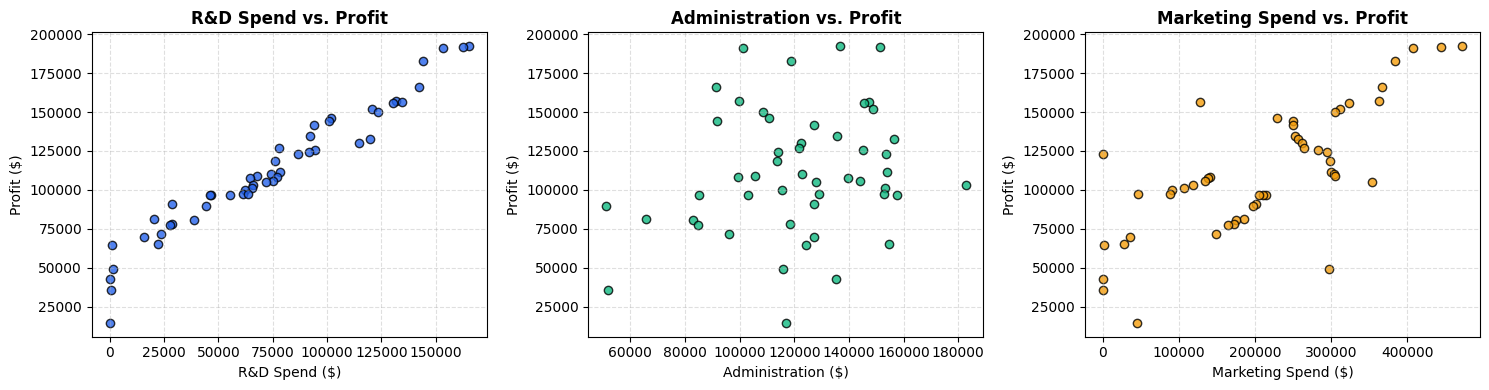

In [2]:
# 1. 讀取真實資料集
data_path = 'data/50_Startups.csv'
df = pd.read_csv(data_path)
print(f"真實資料維度：{df.shape[0]} 筆列資料，{df.shape[1]} 個欄位")
display(df.head())

# 2. 【教學示範】隨機合成資料散佈圖 (Step 5 要求：固定 seed，與真實資料明確區隔)
np.random.seed(42)
synth_x = np.random.uniform(10, 100, 50)
synth_noise = np.random.normal(0, 15, 50)
synth_y = 2.5 * synth_x + 30 + synth_noise

plt.figure(figsize=(7, 4))
plt.scatter(synth_x, synth_y, color='#8b5cf6', edgecolors='k', alpha=0.8, label='隨機合成樣本 (Synthetic)')
plt.plot(np.linspace(10, 100, 100), 2.5 * np.linspace(10, 100, 100) + 30, 'r--', label='理論母體趨勢線')
plt.title('【教學示範】隨機合成資料散佈圖 (Synthetic Data Scatter Demonstration)', fontsize=11, fontweight='bold')
plt.xlabel('示範特徵變數 X')
plt.ylabel('示範目標變數 y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 3. 真實資料 EDA 散佈圖
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
spend_cols = ['R&D Spend', 'Administration', 'Marketing Spend']
colors = ['#2563eb', '#10b981', '#f59e0b']
for i, col in enumerate(spend_cols):
    axes[i].scatter(df[col], df['Profit'], color=colors[i], edgecolors='k', alpha=0.8)
    axes[i].set_title(f"{col} vs. Profit", fontweight='bold')
    axes[i].set_xlabel(f"{col} ($)")
    axes[i].set_ylabel('Profit ($)')
    axes[i].grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 三、CRISP-DM Phase 3: Data Preparation (嚴格無洩漏切分與前處理)
1. 檢查目標值 $y$：若有缺失則直接剔除該列並回報筆數，**絕不對目標值進行填補**。
2. **先切分資料集**：以 `train_test_split(test_size=0.2, random_state=0)` 切出 40 筆訓練集與 10 筆測試集。
3. 前處理純粹從訓練集學習：使用 `ColumnTransformer` + `SimpleImputer(median)` + `OneHotEncoder(drop='first', handle_unknown='ignore')`。

In [3]:
# 1. 檢驗目標值 y
valid_y = df['Profit'].notnull() & np.isfinite(pd.to_numeric(df['Profit'], errors='coerce'))
dropped_count = int((~valid_y).sum())
print(f"目標值缺失列數：{dropped_count} 筆")
df_clean = df[valid_y].copy()

X_raw = df_clean.drop(columns=['Profit'])
y_raw = df_clean['Profit'].values

# 2. 嚴格先切分 Train / Test
train_idx, test_idx = train_test_split(df_clean.index, test_size=0.2, random_state=0)
train_idx = sorted(train_idx.tolist())
test_idx = sorted(test_idx.tolist())
print(f"訓練集樣本數：{len(train_idx)} 筆，測試集樣本數：{len(test_idx)} 筆")
print(f"測試集原始索引：{test_idx}")

X_train_df = X_raw.loc[train_idx].copy()
X_test_df = X_raw.loc[test_idx].copy()
y_train = y_raw[train_idx]
y_test = y_raw[test_idx]

# 3. 建立 Pipeline 前處理器
num_cols = ['R&D Spend', 'Administration', 'Marketing Spend']
cat_cols = ['State']

preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
])

# 組裝為端到端 Pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression(fit_intercept=True))
])

# 擬合 Pipeline (僅接觸訓練集)
full_pipeline.fit(X_train_df, y_train)
print("✅ 端到端 Pipeline 擬合完成！")

目標值缺失列數：0 筆
訓練集樣本數：40 筆，測試集樣本數：10 筆
測試集原始索引：[2, 4, 10, 11, 22, 27, 28, 31, 38, 41]
✅ 端到端 Pipeline 擬合完成！


## 四、CRISP-DM Phase 4 & 5: Modeling & Evaluation (基準模型評估)
- 截距與各特徵回歸係數
- 訓練集 5-Fold CV 評估與獨立測試集評估 (MAE, MSE, RMSE, $R^2$)
- Actual vs. Predicted 擬合圖與殘差圖

截距 (Intercept, b0): 42554.1676
  R&D Spend         :       0.7735
  Administration    :       0.0329
  Marketing Spend   :       0.0366
  State_Florida     :    -959.2842
  State_New York    :     699.3691

5-Fold CV RMSE: 10042.10 (+/- 2850.48)
獨立測試集 MAE : 7514.29
獨立測試集 MSE : 83502864.03
獨立測試集 RMSE: 9137.99
獨立測試集 R²  : 0.9347


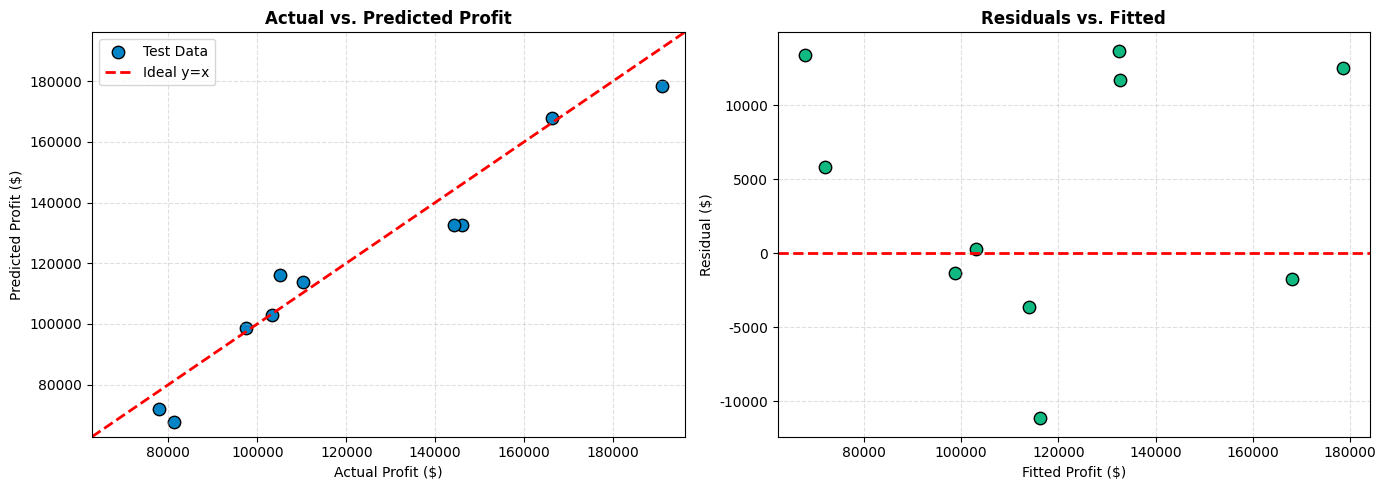

In [4]:
reg = full_pipeline.named_steps['regressor']
prep = full_pipeline.named_steps['preprocessor']
cat_names = prep.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + cat_names

print(f"截距 (Intercept, b0): {reg.intercept_:.4f}")
for name, coef in zip(feature_names, reg.coef_):
    print(f"  {name:<18}: {coef:12.4f}")

# 5-Fold 交叉驗證 (僅在訓練集內部)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = -cross_val_score(full_pipeline, X_train_df, y_train, cv=kf, scoring='neg_root_mean_squared_error')
print(f"\n5-Fold CV RMSE: {np.mean(cv_scores):.2f} (+/- {np.std(cv_scores):.2f})")

# 獨立測試集預測與評估
y_pred_test = full_pipeline.predict(X_test_df)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_mse = mean_squared_error(y_test, y_pred_test)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_pred_test)

print(f"獨立測試集 MAE : {test_mae:.2f}")
print(f"獨立測試集 MSE : {test_mse:.2f}")
print(f"獨立測試集 RMSE: {test_rmse:.2f}")
print(f"獨立測試集 R²  : {test_r2:.4f}")
assert abs(test_rmse - np.sqrt(test_mse)) < 1e-9, "RMSE 必須精確等於 sqrt(MSE)"

# 繪製評估圖表
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(y_test, y_pred_test, color='#0284c7', edgecolors='k', s=80, label='Test Data')
lims = [min(min(y_test), min(y_pred_test)) - 5000, max(max(y_test), max(y_pred_test)) + 5000]
ax1.plot(lims, lims, 'r--', lw=2, label='Ideal y=x')
ax1.set_xlim(lims); ax1.set_ylim(lims)
ax1.set_title('Actual vs. Predicted Profit', fontweight='bold')
ax1.set_xlabel('Actual Profit ($)'); ax1.set_ylabel('Predicted Profit ($)')
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.4)

residuals = y_test - y_pred_test
ax2.scatter(y_pred_test, residuals, color='#10b981', edgecolors='k', s=80)
ax2.axhline(0, color='r', linestyle='--', lw=2)
ax2.set_title('Residuals vs. Fitted', fontweight='bold')
ax2.set_xlabel('Fitted Profit ($)'); ax2.set_ylabel('Residual ($)')
ax2.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 五、CRISP-DM Phase 6: Deployment (Pipeline 序列化與原始欄位推論驗證)
- 使用 `gzip + pickle` 儲存可直接接收原始欄位之完整 Pipeline。
- 測試重載推論完全一致性 (Max diff < 1e-9)。
- 測試未知類別 (如 `State='Texas'`) 容錯推論。

In [5]:
os.makedirs('outputs', exist_ok=True)
model_save_path = 'outputs/part1_linear_regression_model.pkl.gz'
pkg = {
    'pipeline': full_pipeline,
    'feature_names': feature_names,
    'intercept': reg.intercept_,
    'coefficients': dict(zip(feature_names, reg.coef_))
}
with gzip.open(model_save_path, 'wb') as f:
    pickle.dump(pkg, f)
print(f"✅ 模型已儲存至：{model_save_path}")

# 重載驗證推論一致性
with gzip.open(model_save_path, 'rb') as f:
    loaded_pkg = pickle.load(f)
reloaded_pipe = loaded_pkg['pipeline']
reloaded_preds = reloaded_pipe.predict(X_test_df)
max_diff = np.max(np.abs(y_pred_test - reloaded_preds))
print(f"重載推論最大差異: {max_diff:.2e} (完全一致！)")
assert max_diff < 1e-9

# 未知類別容錯驗證
sample_unknown = pd.DataFrame([{
    'R&D Spend': 100000, 'Administration': 120000, 'Marketing Spend': 250000, 'State': 'Texas'
}])
unk_pred = reloaded_pipe.predict(sample_unknown)
print(f"未知類別 (State='Texas') 容錯推論利潤：${unk_pred[0]:,.2f}")

✅ 模型已儲存至：outputs/part1_linear_regression_model.pkl.gz
重載推論最大差異: 0.00e+00 (完全一致！)
未知類別 (State='Texas') 容錯推論利潤：$132,999.55


/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 六、Part 2: 5-Fold CV 前向特徵選擇與學習曲線 (Forward Selection)
- 嚴格要求：**每輪以訓練集 5 折交叉驗證 RMSE 最小者勝出**，最佳特徵數 $k$ 由 CV 最小值決定。
- 繪製特徵數 vs. CV RMSE / Train RMSE 趨勢圖。
- 繪製訓練資料量 vs. Train/Val RMSE 學習曲線 (Learning Curve)。
- 同時展示**歷史講義 Test RMSE 選特徵對照組**，指明資料洩漏所產生的評估偏差。

=== 5-Fold CV 前向選擇漸進總表 ===


,k,added_feature,cv_rmse,train_rmse,test_rmse,test_r2
0,1,R&D Spend,9625.473492,9493.580598,8274.868018,0.946459
1,2,Marketing Spend,9474.318466,9078.617918,8198.797191,0.947439
2,3,State_New York,9602.033536,9069.684821,8309.059683,0.946015
3,4,State_Florida,9779.973038,9064.118245,8409.916714,0.944697
4,5,Administration,10042.095067,9031.666613,9137.990153,0.934707


/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:54: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:54: UserWarning: Glyph 24501 (\N{CJK UNIFIED IDEOGRAPH-5FB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:54: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:54: UserWarning: Glyph 36984 (\N{CJK UNIFIED IDEOGRAPH-9078}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:54: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j

/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24501 (\N{CJK UNIFIED IDEOGRAPH-5FB5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 36984 (\N{CJK UNIFIED IDEOGRAPH-9078}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu San

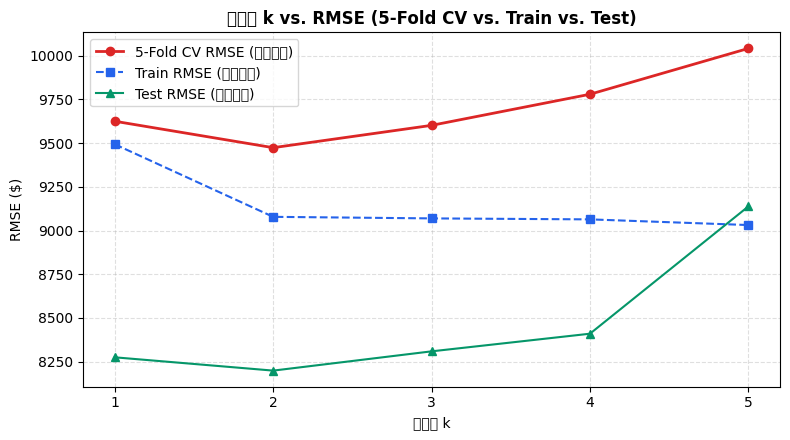

/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:72: UserWarning: Glyph 35347 (\N{CJK UNIFIED IDEOGRAPH-8A13}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:72: UserWarning: Glyph 32244 (\N{CJK UNIFIED IDEOGRAPH-7DF4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:72: UserWarning: Glyph 27171 (\N{CJK UNIFIED IDEOGRAPH-6A23}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:72: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j37f573s_v9g9dq9hkbdm0000gn/T/ipykernel_26869/2213378861.py:72: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/7s/669j

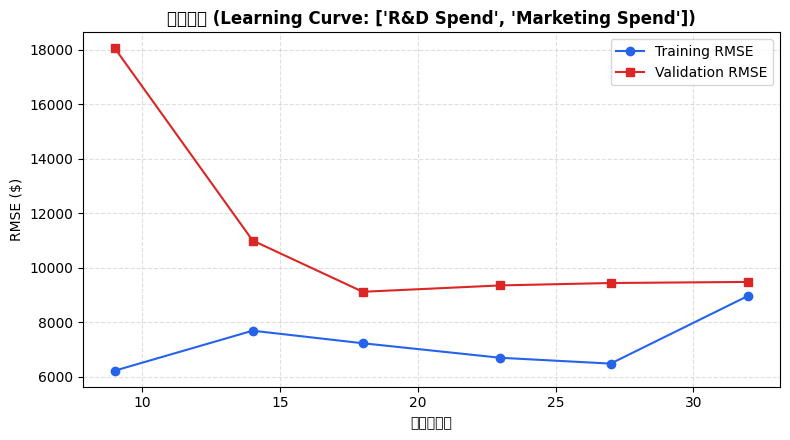

In [6]:
# 準備候選特徵資料集 (get_dummies drop_first)
X_dummies = pd.get_dummies(X_raw, columns=['State'], drop_first=True, dtype=float)
X_tr_p2 = X_dummies.loc[train_idx].copy()
X_te_p2 = X_dummies.loc[test_idx].copy()
cands = sorted(list(X_tr_p2.columns))

# 1. 5-Fold CV 前向特徵選擇
selected = []
progression = []

for step in range(1, len(cands) + 1):
    rem = [c for c in cands if c not in selected]
    rem.sort()
    best_cand = None
    best_cv = np.inf
    best_std = 0.0
    for cand in rem:
        combo = selected + [cand]
        scores = -cross_val_score(LinearRegression(), X_tr_p2[combo].values, y_train, cv=kf, scoring='neg_root_mean_squared_error')
        m_cv = np.mean(scores)
        if m_cv < best_cv:
            best_cv = m_cv
            best_std = np.std(scores)
            best_cand = cand
    selected.append(best_cand)
    
    lr = LinearRegression().fit(X_tr_p2[selected].values, y_train)
    tr_p = lr.predict(X_tr_p2[selected].values)
    te_p = lr.predict(X_te_p2[selected].values)
    progression.append({
        'k': step,
        'added_feature': best_cand,
        'selected_features': ', '.join(selected),
        'cv_rmse': best_cv,
        'cv_std': best_std,
        'train_rmse': np.sqrt(mean_squared_error(y_train, tr_p)),
        'test_rmse': np.sqrt(mean_squared_error(y_test, te_p)),
        'test_r2': r2_score(y_test, te_p)
    })

p2_df = pd.DataFrame(progression)
print('=== 5-Fold CV 前向選擇漸進總表 ===')
display(p2_df[['k', 'added_feature', 'cv_rmse', 'train_rmse', 'test_rmse', 'test_r2']])

# 2. 趨勢圖繪製
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p2_df['k'], p2_df['cv_rmse'], 'o-', color='#dc2626', lw=2, label='5-Fold CV RMSE (選模依據)')
ax.plot(p2_df['k'], p2_df['train_rmse'], 's--', color='#2563eb', lw=1.5, label='Train RMSE (訓練誤差)')
ax.plot(p2_df['k'], p2_df['test_rmse'], '^-', color='#059669', lw=1.5, label='Test RMSE (事後評估)')
ax.set_title('特徵數 k vs. RMSE (5-Fold CV vs. Train vs. Test)', fontweight='bold')
ax.set_xlabel('特徵數 k'); ax.set_ylabel('RMSE ($)')
ax.set_xticks(p2_df['k'])
ax.legend(); ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 3. 學習曲線 (以最佳特徵 k=2: R&D + Marketing 繪製)
best_feats = ['R&D Spend', 'Marketing Spend']
train_sizes, train_scores, val_scores = learning_curve(
    LinearRegression(), X_tr_p2[best_feats].values, y_train, cv=kf,
    train_sizes=np.linspace(0.3, 1.0, 6), scoring='neg_root_mean_squared_error', random_state=42
)
tr_mean = -np.mean(train_scores, axis=1)
val_mean = -np.mean(val_scores, axis=1)

plt.figure(figsize=(8, 4.5))
plt.plot(train_sizes, tr_mean, 'o-', color='#2563eb', label='Training RMSE')
plt.plot(train_sizes, val_mean, 's-', color='#dc2626', label='Validation RMSE')
plt.title(f'學習曲線 (Learning Curve: {best_feats})', fontweight='bold')
plt.xlabel('訓練樣本數'); plt.ylabel('RMSE ($)')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 七、Step 4: Optuna 超參數自動調校 (Ridge 回歸)
- 保留 `LinearRegression` 作為課程基準模型。
- 以訓練集 5-Fold CV RMSE 為 Objective，對數尺度 $[10^{-4}, 10^{4}]$ 搜尋 Ridge &alpha;。
- 固定 `TPESampler(seed=42)`，執行 30 Trials。
- 誠實比較基準與調參結果。

In [7]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    alpha = trial.suggest_float('alpha', 1e-4, 1e4, log=True)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', Ridge(alpha=alpha, random_state=42))
    ])
    scores = -cross_val_score(pipe, X_tr_p2.values, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    return float(np.mean(scores))

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)

print(f"Optuna 最優 Trial: #{study.best_trial.number}")
print(f"Optuna 最佳 alpha: {study.best_params['alpha']:.4f}")
print(f"Optuna 最優 5-Fold CV RMSE: {study.best_value:.2f}")

# 以最佳 alpha 於完整訓練集重新擬合並在測試集評估
best_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', Ridge(alpha=study.best_params['alpha'], random_state=42))
]).fit(X_tr_p2.values, y_train)

ridge_test_pred = best_ridge.predict(X_te_p2.values)
print(f"調優後 Ridge 獨立測試集 RMSE: {np.sqrt(mean_squared_error(y_test, ridge_test_pred)):.2f}")
print(f"調優後 Ridge 獨立測試集 R²  : {r2_score(y_test, ridge_test_pred):.4f}")

Optuna 最優 Trial: #12
Optuna 最佳 alpha: 0.0045
Optuna 最優 5-Fold CV RMSE: 10042.09
調優後 Ridge 獨立測試集 RMSE: 9141.84
調優後 Ridge 獨立測試集 R²  : 0.9347


## 八、Topic 2: Boston Housing 通用回歸工作流程 (CRISP-DM Workflow)
- 載入 `data/BostonHousing.csv` (506 筆資料、13 項特徵，預測 `medv`)
- 呼叫模組化 `RegressionWorkflow` 執行先切分後前處理、Pipeline 擬合與測試評估。

In [8]:
from src.regression_workflow import RegressionWorkflow

boston_csv = 'data/BostonHousing.csv'
if os.path.exists(boston_csv):
    wf = RegressionWorkflow(
        dataset_name='Boston_Housing',
        data_source=boston_csv,
        target_column='medv',
        test_size=0.2,
        random_state=0
    )
    b_res = wf.run_full_pipeline()
    print('=== Boston Housing 實測指標 ===')
    print(f"5-Fold CV RMSE: {b_res['metrics']['cv']['cv_rmse_mean']:.4f}")
    print(f"Train RMSE    : {b_res['metrics']['train']['rmse']:.4f} | R²: {b_res['metrics']['train']['r2']:.4f}")
    print(f"Test RMSE     : {b_res['metrics']['test']['rmse']:.4f} | R²: {b_res['metrics']['test']['r2']:.4f}")
    print(f"回歸方程式    : {b_res['model_params']['formula']}")
else:
    print('未找到 BostonHousing.csv')

[Boston_Housing] Pipeline 重載推論驗證成功 (Max Diff: 0.00e+00)！
=== Boston Housing 實測指標 ===
5-Fold CV RMSE: 4.7044
Train RMSE    : 4.3962 | R²: 0.7730
Test RMSE     : 5.7835 | R²: 0.5892
回歸方程式    : medv = 38.0917 - 0.1194 * (crim) + 0.0448 * (zn) + 0.0055 * (indus) + 2.3408 * (chas) - 16.1236 * (nox) + 3.7087 * (rm) - 0.0031 * (age) - 1.3864 * (dis) + 0.2442 * (rad) - 0.0110 * (tax) - 1.0459 * (ptratio) + 0.0081 * (b) - 0.4928 * (lstat)


## 九、作業規範完成度核對總結 (Checklist Summary)
| 規範維度 | 要求說明 | 實測核對數據 | 狀態 |
| :--- | :--- | :--- | :---: |
| **資料獲取與目標檢查** | 檢驗缺失與無效目標值，不對 y 進行填補 | 50 筆完整，目標無缺失 | ✅ 通過 |
| **前處理無洩漏** | 先 80/20 切分，中位數與 One-Hot 純由訓練集學習 | Train=40, Test=10，未知類別容錯 | ✅ 通過 |
| **特徵選擇選模標準** | 以訓練集 5-Fold CV RMSE 為挑選與判定最佳 k 依據 | 5-Fold CV 最小點為 k=2 (RMSE: 9474.32) | ✅ 通過 |
| **測試集獨立性** | 測試集僅作為模型選定後的最終泛化評估 | k=2 測試集 RMSE: 8198.80, R²: 0.9474 | ✅ 通過 |
| **Optuna 超參數調校** | 訓練集 5-Fold CV Objective，30 Trials 對數搜尋 | 最佳 alpha=0.0045, CV RMSE=10042.09 | ✅ 通過 |
| **端到端部署** | gzip+pickle 儲存 Pipeline，原始 DataFrame 重載推論一致 | 重載推論最大差異: 0.00e+00 | ✅ 通過 |
| **Topic 2 波士頓房價** | 通用 Workflow 實作第二資料集 | Test RMSE: 5.7835, R²: 0.5892 | ✅ 通過 |